# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import EGYBCDDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/egy_bcd/256/",
}
dataset = EGYBCDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 6091


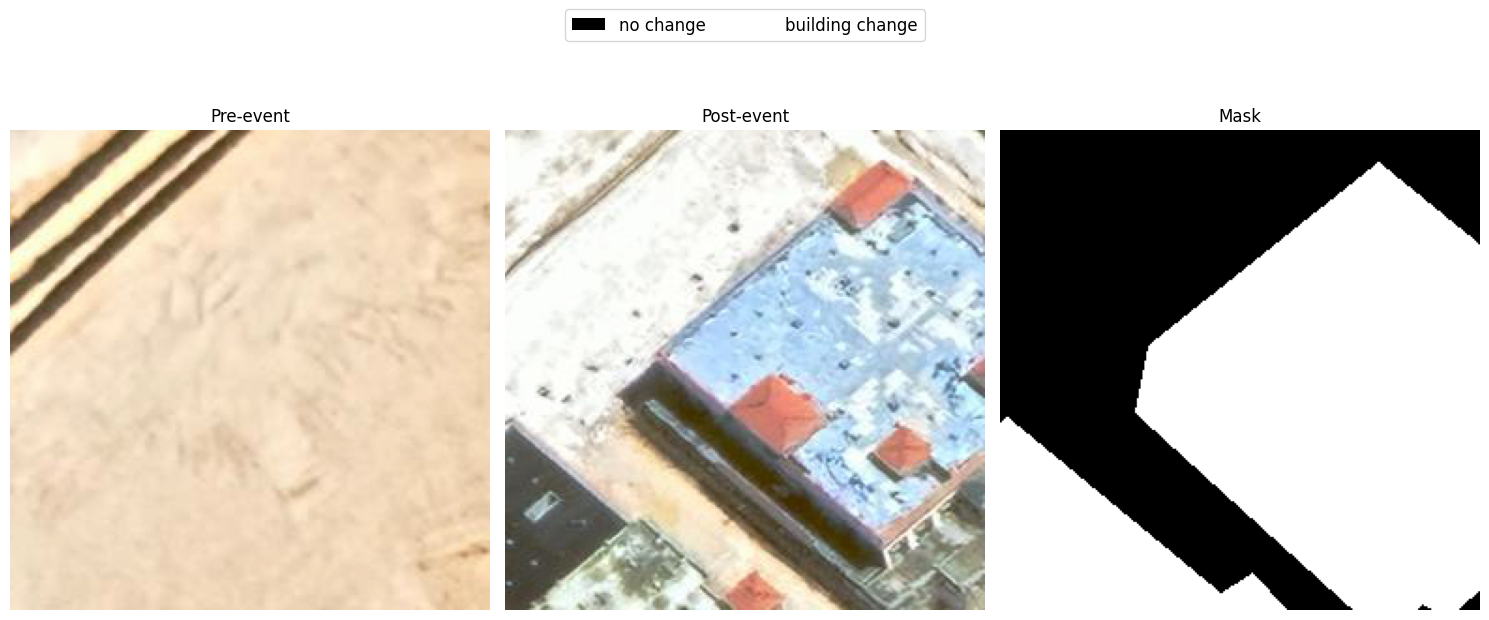

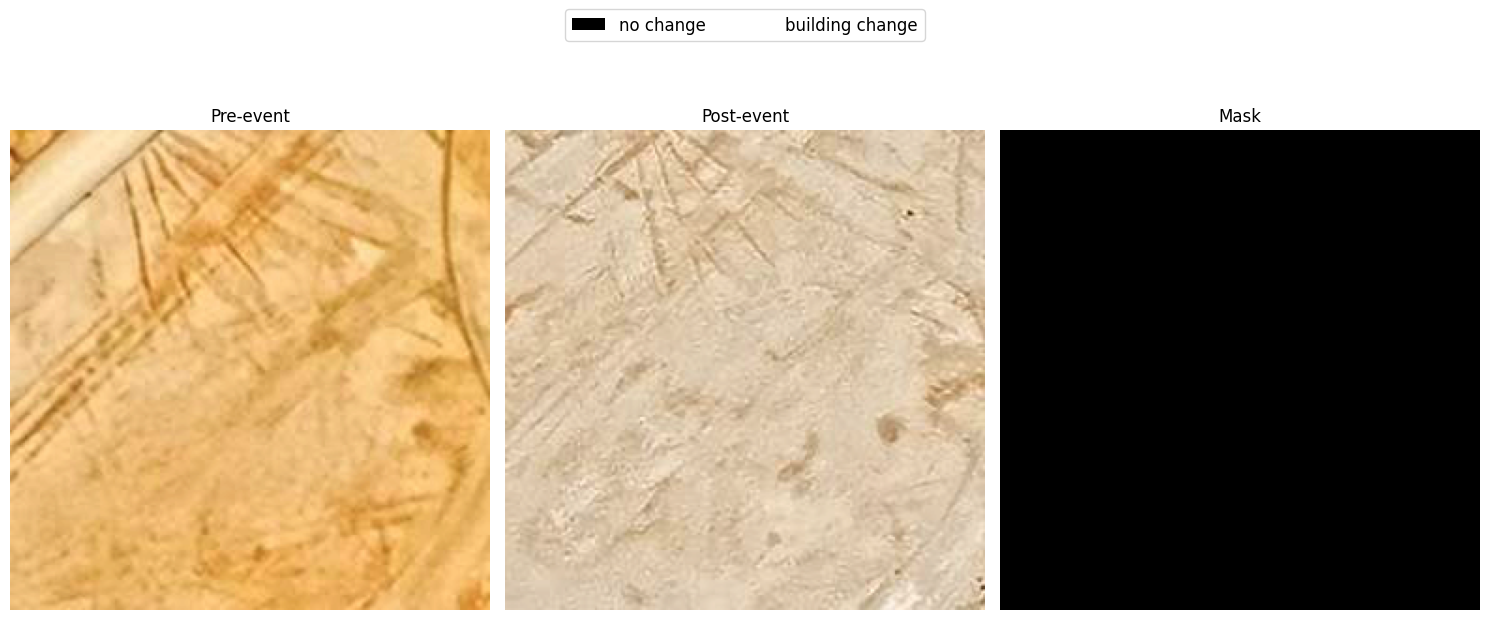

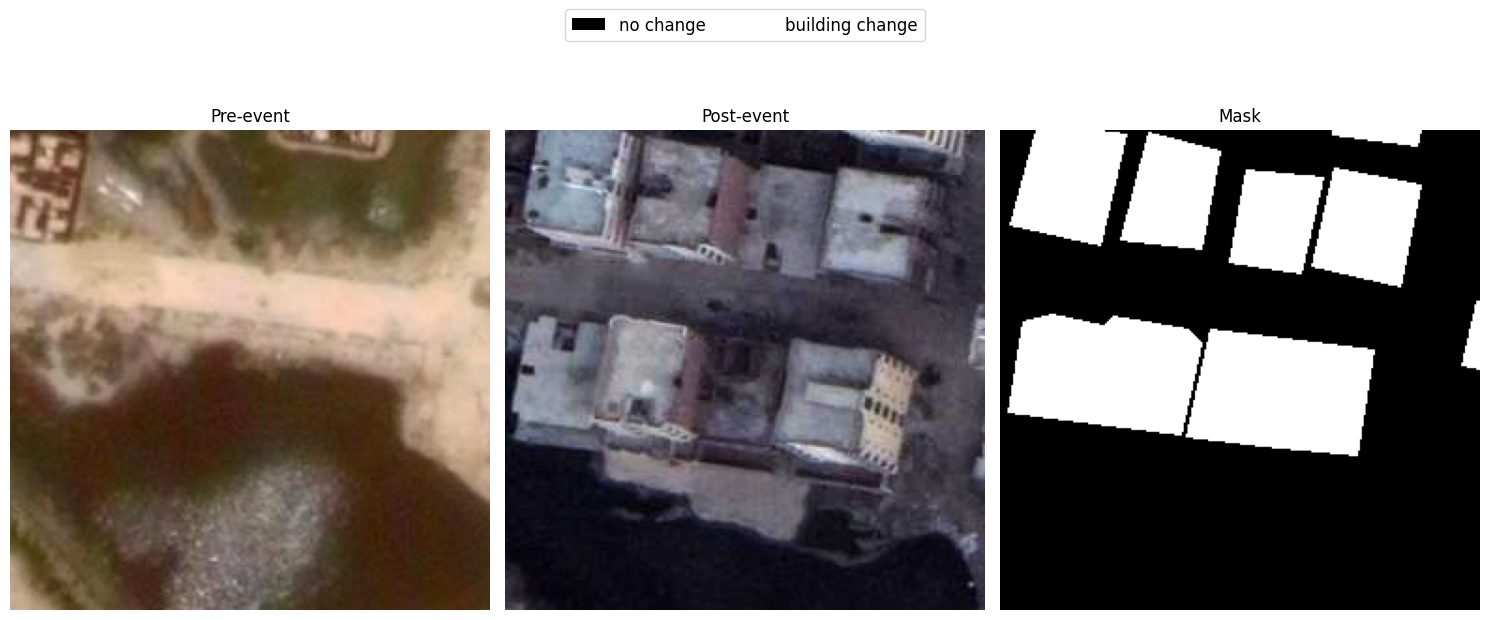

In [6]:
dataset.show_image(500);
dataset.show_image(15);
dataset.show_image(4500);

In [32]:
dataset.data_distribution_table()

,Number of pixels
no change,371350339.0
building change,27829437.0


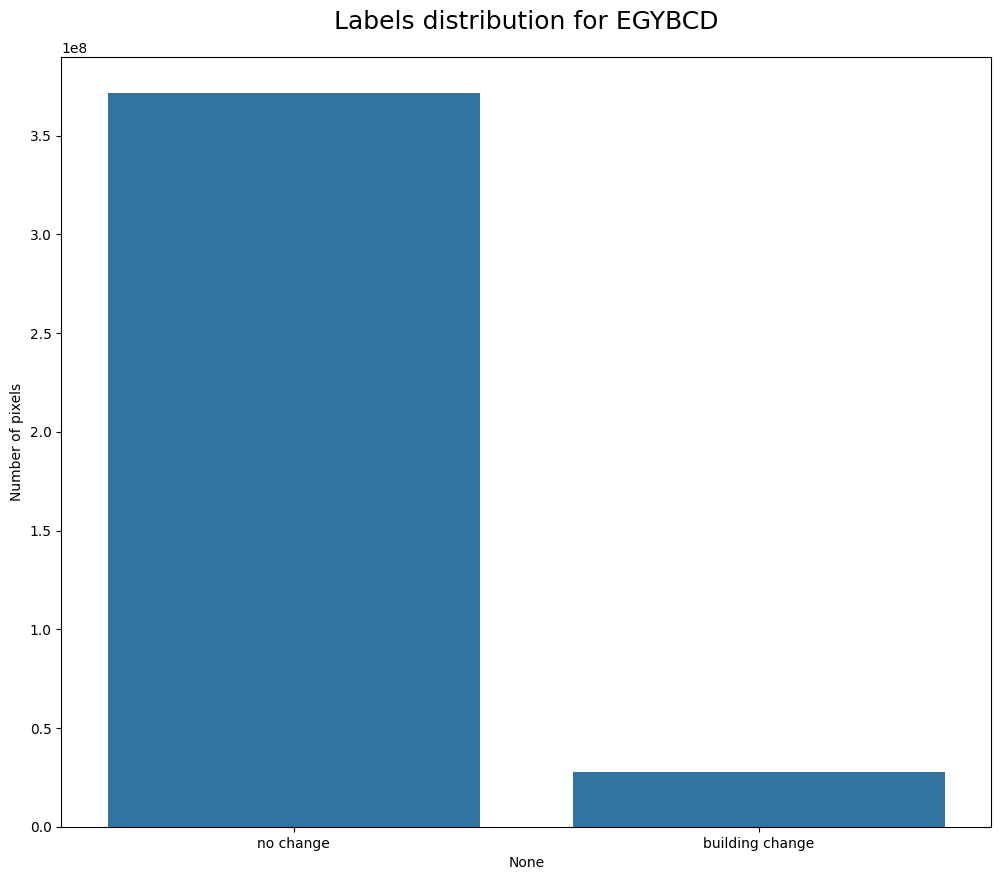

In [33]:
dataset.data_distribution_barchart();

## Load training and test data

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/egy_bcd/256/",
    "csv_file": "./data/egy_bcd/256/egy_bcd_train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = EGYBCDDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/egy_bcd/256/",
    "csv_file": "./data/egy_bcd/256/egy_bcd_val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = EGYBCDDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(3655, 1218)

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/egy_bcd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [9]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-28 09:56:38,218 INFO Starting training.
training: 100%|██████████| 229/229 [01:52<00:00,  2.04it/s]
2026-01-28 09:58:30,468 INFO epoch: 1, loss:  0.17904
testing on train set: 100%|██████████| 229/229 [03:26<00:00,  1.11it/s]
2026-01-28 10:01:58,245 INFO Accuracy:0.9195467780618106, Accuracy per Class:[0.9137368  0.92535676], Precision Micro:0.9339708422917015, Precision Macro:0.6744538873870743, Precision Weighted:0.9094613348619194, Precision per Class:[0.9476352  0.40127258], Recall Micro:0.9029280760382823, Recall Macro:0.5495922457528367, Recall Weighted:0.9029280760382823, Recall per Class:[0.96032283 0.13886167], F1_score Micro:0.9181871547651551, F1_score Macro:0.5801305052252743, F1_score Weighted:0.9017018060130343, F1_score per Class:[0.95393683 0.20632418], IOU:0.8487486156312296, IOU mean:0.513479555108532, IOU per Class:[0.91193042 0.11502869]
training: 100%|██████████| 229/229 [01:53<00:00,  2.02it/s]
2026-01-28 10:03:51,566 INFO epoch: 2, loss:  0.10795
testing 

## Predictions

2026-01-28 13:03:35,697 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/egy_bcd/checkpoint.pth.tar
2026-01-28 13:03:36,181 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/egy_bcd/checkpoint.pth.tar at epoch 51


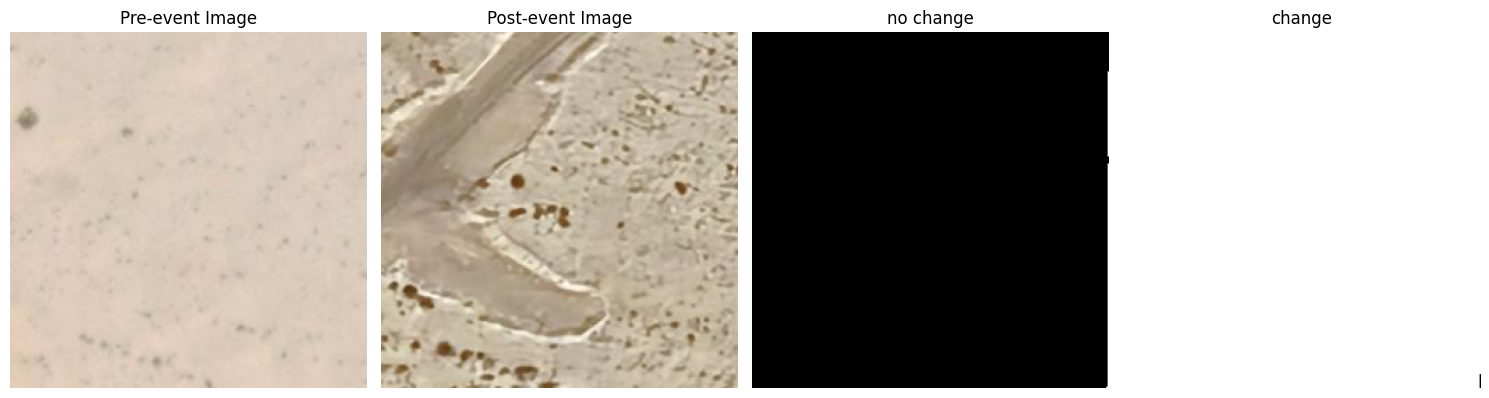

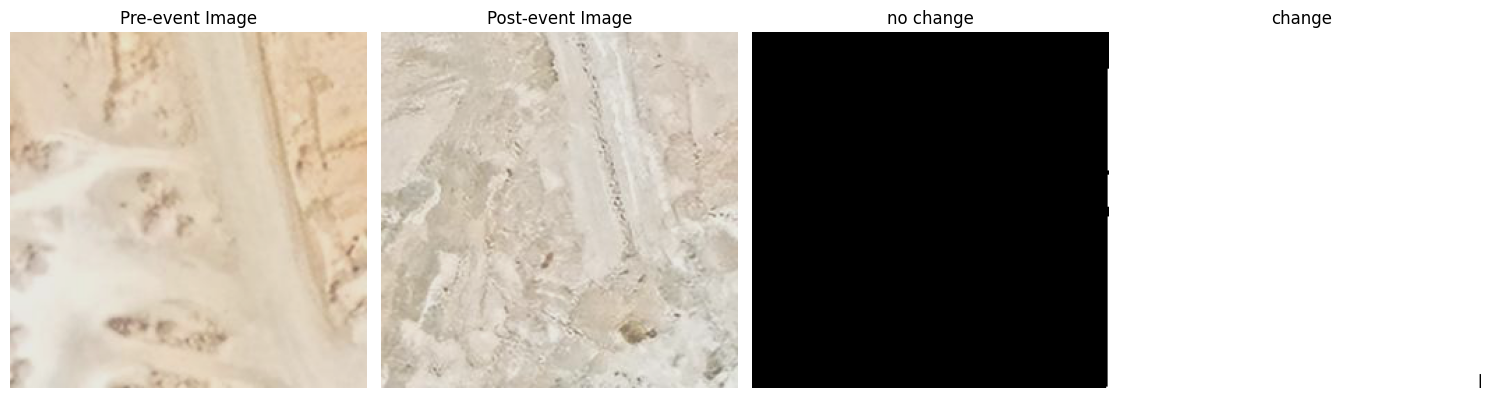

In [ ]:
model_path = "./data/experiments/egy_bcd/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("./data/egy_bcd/256/A/Mansoura_1_21.png")
image2 = image_loader("./data/egy_bcd/256/B/Mansoura_1_21.png")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("./data/egy_bcd/256/A/Galala_10_16.png")
image2 = image_loader("./data/egy_bcd/256/B/Galala_10_16.png")
fig = model.predict_masks(image1, image2, labels, transform)